In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
import seaborn as sns

In [42]:
df = pd.read_csv('./abalone/abalone.data',header=None,names=['sex','length','diameter','height','whole_weight','shucked_weight','viscera_weight','shell_weight','rings'])
df['sex'] = df.pop('sex')
print(df.shape)
df.head()

(4177, 9)


,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings,sex
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,M
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,M
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,F
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,M
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,I


In [43]:
print('NaN values of each columns:')
print(df.isna().sum())

NaN values of each columns:
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
sex               0
dtype: int64


In [44]:
print('Count of duplicated rows:')
print(df.duplicated().sum())

Count of duplicated rows:
0


In [45]:
print('Datatypes of each columns:')
print(df.dtypes)

Datatypes of each columns:
length            float64
diameter          float64
height            float64
whole_weight      float64
shucked_weight    float64
viscera_weight    float64
shell_weight      float64
rings               int64
sex                object
dtype: object


# **Preprocessing**

In [46]:
from sklearn.model_selection import train_test_split

df_train,df_test = train_test_split(df,test_size=0.2,random_state=42)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from modules.autolog import ASLT
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler,OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
from copy import deepcopy

class OutlierRemover():
    '''
    Removes outlier by using LOF.
    '''
    def __init__(self,target=['sex']):
        self._pl = Pipeline([
            ('scaler',StandardScaler()),
            ('outlier',LocalOutlierFactor(novelty=True))
        ])
        self.target = target

    def fit(self,df:pd.DataFrame):
        self.is_fitted = True
        self._pl.fit(df.drop(self.target,axis=1))

    def transform(self,df:pd.DataFrame):
        if not hasattr(self,'is_fitted'):
            raise AttributeError('The module has not been fitted. Fit first!')
        self.outliers = self._pl.predict(df.drop(self.target,axis=1))
        self.outliers = np.where(self.outliers == -1,1,0).astype(bool)
        df_dropped = df[~self.outliers]
        return df_dropped

    def fit_transform(self,df:pd.DataFrame):
        self.fit(df)
        return self.transform(df)

    def __len__(self):
        if not hasattr(self,'is_fitted'):
            raise AttributeError('The module has not been fitted. Fit first!')
        return self.outliers.sum()

    def outlier_pairplot(self,df:pd.DataFrame,outliers:pd.Series):
        df['outliers'] = outliers
        sns.pairplot(df,hue='outliers')
        plt.show()

In [ ]:
from modules.preprocess import OutlierRemover,Preprocessor

out_remover = OutlierRemover()
out_remover.fit(df)
df_train_out = out_remover.transform(df)
df_train_out

,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings,sex
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.1500,15,M
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.0700,7,M
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.2100,9,F
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.1550,10,M
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.0550,7,I
...,...,...,...,...,...,...,...,...,...
4172,0.565,0.450,0.165,0.8870,0.3700,0.2390,0.2490,11,F
4173,0.590,0.440,0.135,0.9660,0.4390,0.2145,0.2605,10,M
4174,0.600,0.475,0.205,1.1760,0.5255,0.2875,0.3080,9,M
4175,0.625,0.485,0.150,1.0945,0.5310,0.2610,0.2960,10,F


# **Modelling**

In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
import optuna

def objective(trial):
    svc_C = trial.suggest_float('C',1e-2,1e1),
    svc_kernel = trial.suggest_categorical('kernel',['linear','poly','rbf'])

    svc = SVC(C=svc_C[0],kernel=svc_kernel,gamma='scale',degree=4)
    score = cross_val_score(svc,X_train_pr,y_train_pr,n_jobs=4,cv=4)
    accuracy = score.mean()
    return accuracy

svc_study = optuna.create_study(direction='maximize')
svc_study.optimize(objective,n_trials=100)

[I 2026-11-15 15:32:01,451] A new study created in memory with name: no-name-33a59889-ffaf-48a9-9d1a-42f71cb4c895
[I 2026-11-15 15:32:03,001] Trial 0 finished with value: 0.4408832795102342 and parameters: {'C': 2.919940784359711, 'kernel': 'poly'}. Best is trial 0 with value: 0.4408832795102342.
[I 2026-11-15 15:32:03,338] Trial 1 finished with value: 0.5536782940175844 and parameters: {'C': 6.997033580396087, 'kernel': 'linear'}. Best is trial 1 with value: 0.5536782940175844.
[I 2026-11-15 15:32:03,654] Trial 2 finished with value: 0.5536782940175844 and parameters: {'C': 6.6235234748795015, 'kernel': 'linear'}. Best is trial 1 with value: 0.5536782940175844.
[I 2026-11-15 15:32:04,001] Trial 3 finished with value: 0.5542832549165424 and parameters: {'C': 8.106944376533326, 'kernel': 'linear'}. Best is trial 3 with value: 0.5542832549165424.
[I 2026-11-15 15:32:04,197] Trial 4 finished with value: 0.5506538555003498 and parameters: {'C': 1.5398630029121962, 'kernel': 'linear'}. Best

In [ ]:
def objective(trial):
    rf_n_estimators = trial.suggest_int('n_estimators',10,500),
    rf_criterion = trial.suggest_categorical('criterion',['entropy','gini','log_loss'])

    rf = RandomForestClassifier(n_estimators=rf_n_estimators[0],criterion=rf_criterion)
    score = cross_val_score(rf,X_train_pr,y_train_pr,n_jobs=4,cv=4)
    accuracy = score.mean()
    return accuracy

rf_study = optuna.create_study(direction='maximize')
rf_study.optimize(objective,n_trials=100)

[I 2026-11-15 15:32:25,881] A new study created in memory with name: no-name-406382b7-c4e1-428e-9577-f69832129355
[I 2026-11-15 15:32:27,653] Trial 0 finished with value: 0.5563942134556772 and parameters: {'n_estimators': 315, 'criterion': 'entropy'}. Best is trial 0 with value: 0.5563942134556772.
[I 2026-11-15 15:32:29,576] Trial 1 finished with value: 0.5576037692760378 and parameters: {'n_estimators': 479, 'criterion': 'gini'}. Best is trial 1 with value: 0.5576037692760378.
[I 2026-11-15 15:32:30,489] Trial 2 finished with value: 0.5512544246686439 and parameters: {'n_estimators': 227, 'criterion': 'gini'}. Best is trial 1 with value: 0.5576037692760378.
[I 2026-11-15 15:32:31,665] Trial 3 finished with value: 0.5530674774777412 and parameters: {'n_estimators': 210, 'criterion': 'log_loss'}. Best is trial 1 with value: 0.5576037692760378.
[I 2026-11-15 15:32:33,326] Trial 4 finished with value: 0.545203717746398 and parameters: {'n_estimators': 406, 'criterion': 'gini'}. Best is 

In [ ]:
svc = SVC(**svc_study.best_params)
svc.fit(X_train_pr,y_train_pr)
y_svc = svc.predict(X_test_pr)

rf = RandomForestClassifier(**rf_study.best_params)
rf.fit(X_train_pr,y_train_pr)
y_rf = rf.predict(X_test_pr)

SVC =======================================================================


,Male,Female,Infant,accuracy,macro avg,weighted avg
precision,0.482094,0.486034,0.744898,0.575359,0.571008,0.567262
recall,0.570033,0.332061,0.820225,0.575359,0.574106,0.575359
f1-score,0.522388,0.394558,0.780749,0.575359,0.565898,0.564841
support,307.000000,262.000000,267.000000,0.575359,836.000000,836.000000


RF ========================================================================


,Male,Female,Infant,accuracy,macro avg,weighted avg
precision,0.481366,0.443396,0.735099,0.563397,0.553287,0.550503
recall,0.504886,0.358779,0.831461,0.563397,0.565042,0.563397
f1-score,0.492846,0.396624,0.780316,0.563397,0.556596,0.554502
support,307.000000,262.000000,267.000000,0.563397,836.000000,836.000000


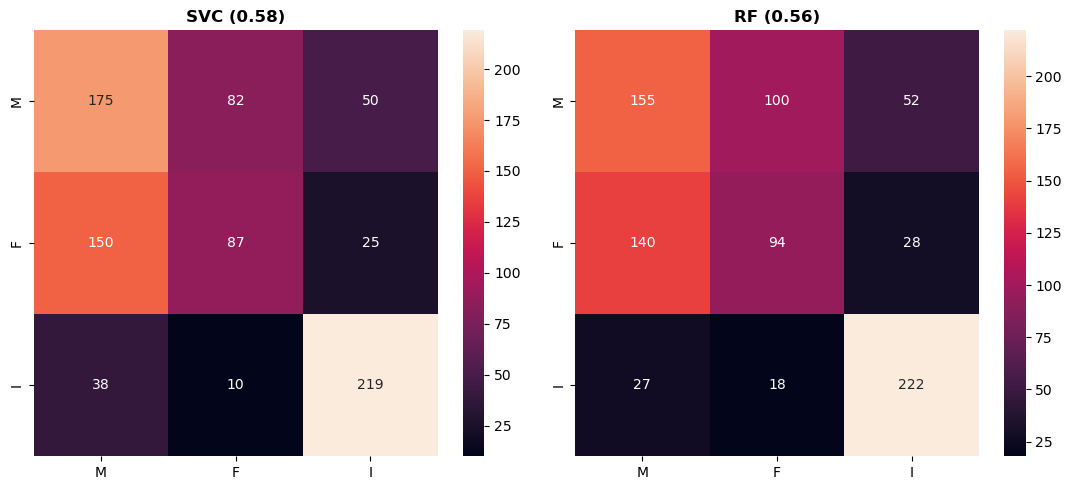

In [ ]:
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,confusion_matrix,classification_report

svc_rpt = pd.DataFrame(classification_report(y_test_pr,y_svc,output_dict=True)).rename(columns={'0.0':'Male','1.0':'Female','2.0':'Infant'})
rf_rpt = pd.DataFrame(classification_report(y_test_pr,y_rf,output_dict=True)).rename(columns={'0.0':'Male','1.0':'Female','2.0':'Infant'})
print('SVC =======================================================================')
display(svc_rpt)

print('RF ========================================================================')
display(rf_rpt)

plt.figure(figsize=(11,5))
plt.subplot(1,2,1)
sns.heatmap(confusion_matrix(y_test_pr,y_svc),annot=True,fmt='2d',xticklabels=['M','F','I'],yticklabels=['M','F','I'])
plt.title(f'SVC ({accuracy_score(y_test_pr,y_svc):.2f})',weight='bold')

plt.subplot(1,2,2)
sns.heatmap(confusion_matrix(y_test_pr,y_rf),annot=True,fmt='2d',xticklabels=['M','F','I'],yticklabels=['M','F','I'])
plt.title(f'RF ({accuracy_score(y_test_pr,y_rf):.2f})',weight='bold')

plt.tight_layout()
plt.show()